# Normalize sqY2H consensus scores

This script applies various QA/QC steps and then computes a normalized interaction score. For QA/QC we:

1.   Check whether 6 media controls on each mega-plate meet various condition-specific thresholds
2.   Check for autoactivation mating failures
3.   Adjust consensus score based on autoactivation score and filter if score invalid

In [2]:
import polars as pl 
import pandas as pd
import numpy as np
import seaborn as sns
import sys

sys.path.append("../../../1_allele_collection/2_analysis")
from plot_utils import *

sys.path.append("../..")
from analyses_plot_utils import *


In [3]:
inputs_dir = "../1_inputs/sqY2H"
outputs_dir = "../3_outputs/sqY2H"
meta_inputs = "../../../1_allele_collection/1_inputs"
meta_outputs = "../../../1_allele_collection/3_outputs"

scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
max_score = 4
aa_id = 0.0
rrs_id = 999999.0

In [4]:
def df_to_dict_variants(df):
    if isinstance(df, pl.DataFrame):
        df = df.to_pandas()
        
    if 'media_control' in df.columns:
        df = df[df['media_control'] == False].copy()
        
    scoring_conditions = ['LWH1', 'LWH10', 'LWH25', 'LWA']
        
    if 'condition_name' in df.columns:
        df = df[df['condition_name'].isin(scoring_conditions)].copy()
    
    cols_to_keep = ['db_orf_id', 'ad_orf_id', 'db_mut_id', 'retest_batch']

    df = df[cols_to_keep].copy()

    df[['db_orf_id', 'ad_orf_id', 'db_mut_id']] = df[['db_orf_id', 'ad_orf_id', 'db_mut_id']].map(float).map(int)
        
    def filter_df(df):
        df = df[(df.ad_orf_id != 0) 
                & (df.db_mut_id != 999999)].copy()
        
        return df
    
    df = filter_df(df)
    
    df_dict = {}
    
    assay_array = ["VUSAPWT1B1","VUSAPWT1B2","VUSAPWT2B1","VUSAPWT6B1"]
    
    for retest_batch in assay_array:
        df_assay = df[df['retest_batch'] == retest_batch]
        df_dict[retest_batch] = {}
        for db_orf_id, df_db in df_assay.sort_values('db_orf_id').groupby('db_orf_id'):
            df_dict[retest_batch][db_orf_id] = {}
            for i, row in df_db.sort_values('db_mut_id').iterrows():
                db_mut_id = row['db_mut_id']
                ad_orf_id = row['ad_orf_id']
                if db_mut_id not in df_dict[retest_batch][db_orf_id].keys():
                    df_dict[retest_batch][db_orf_id][db_mut_id] = {ad_orf_id}
                else:
                    df_dict[retest_batch][db_orf_id][db_mut_id].add(ad_orf_id)
                    
    return df_dict

## Apply all QA/QC thresholds

In [5]:
# get media control thresholds
media_score_thresholds = pd.read_csv(f"{inputs_dir}/media_control_score_thresholds.csv")
media_score_thresholds.rename(columns={'control_96': 'scoring_pos'}, inplace=True)

In [6]:
scores = pd.read_csv(f"{outputs_dir}/2_raw_consensus_scores.csv") 

# Split into media controls
media_ctrls = scores[scores['media_control']]
scores = scores[~scores['media_control']]

# Check media controls
media_ctrls = media_ctrls[['db_orf_id', 'condition_name', 'retest_batch', 'consensus_score']]
media_ctrls[['scoring_pos', 'retest_pla']] = media_ctrls['db_orf_id'].str.split('_', n=1, expand=True)
media_ctrls = media_ctrls.merge(media_score_thresholds, on=['scoring_pos', 'condition_name'])
media_ctrls['score_in_bounds'] = media_ctrls['consensus_score'].between(media_ctrls['lower_bound'], media_ctrls['upper_bound'], inclusive='both')

# replace failure due to variable scoring (99999) with NaN to group with other technical failures
scores['consensus_score'] = scores['consensus_score'].replace(99999, np.nan)

# add IDs for groups used for filtering
scores = pl.DataFrame(scores)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)


scores = scores.with_columns(
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_group"),
    pl.concat_str([
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('condition_name').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("db_condition_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('db_mut_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("ppi_group"),
    pl.concat_str([
            pl.col('ad_orf_id').cast(pl.String),
            pl.col('db_orf_id').cast(pl.String),
            pl.col('retest_batch').cast(pl.String)
    ], separator="_").alias("edge_group")
)

dict_before_qc = df_to_dict_variants(scores)

## Sequencing filters

In [7]:
# read in sequence confirmation files
ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
    "swim_seq_validated": "seq_ad"
}).select([
    "ad_orf_id", "assay_id", "seq_ad"
])

db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "db_mut_id", "seq_db"])

db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
    "disease_orf_id": "db_orf_id",
    "swim_seq_validated": "seq_db"
}).select(["db_orf_id", "seq_db"]).with_columns(
    pl.lit(0).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "seq_db"])

db_seq = pl.concat([db_var_seq, db_ref_seq])


# cast all to same format
scores = scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

db_seq = db_seq.with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("seq_db").cast(pl.String).alias("seq_db")
)

ad_seq = ad_seq.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

final_sequencing_df = pd.read_csv(f"{meta_outputs}/VarChampSeqConfirmationResult_final_call.tsv", sep="\t").rename({'mut_id': 'db_mut_id', 'orf_id': 'db_orf_id'}, axis=1)

final_sequencing_df

# Convert final_sequencing_df to polars and ensure matching data types
final_sequencing_pl = pl.DataFrame(final_sequencing_df).with_columns(
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id")
).select(["db_orf_id", "db_mut_id", "db_seq_final"])

# Join the db_seq_final column onto scores
scores = scores.join(final_sequencing_pl, on=["db_orf_id", "db_mut_id"], how="left")

print(f"Scores shape: {scores.shape}")
print(f"Unique values in db_seq_final: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")


scores_aa_rrs = scores.filter(
    (pl.col("ad_orf_id") == float(aa_id)) | 
    (pl.col("db_mut_id") == rrs_id)
)

scores = scores.filter(
    (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & 
    (
        (pl.col("db_mut_id") == 0) |  # WT is always good
        (pl.col("db_seq_final") == "Y")  # Use the final Y/N decision from sequence confirmation
    )
)

scores = pl.concat([scores, scores_aa_rrs])

print("After sequence confirmation filtering:")
print(f"Scores shape: {scores.shape}")
print(f"Unique db_seq_final values: {scores.select('db_seq_final').unique().to_pandas()['db_seq_final'].tolist()}")

scores_after_seq = scores.clone()
scores

Scores shape: (71490, 26)
Unique values in db_seq_final: [None, 'Y', 'N']
After sequence confirmation filtering:
Scores shape: (48282, 26)
Unique db_seq_final values: ['Y', None, 'N']


ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final
i64,f64,i64,i64,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str
100014221,null,71001,205675,"""LWH25""","""VUSAPWT2B1""",false,0.0,"""WFDC12""","""UBQLN2""","""Pro506Thr""","""1516C>A""","""ENSG00000188021""","""CEGS2""","""1_Pathogenic""",null,1.0,"""UBQLN2_Pro506Thr""","""2""","""71001.0_205675.0_VUSAPWT2B1""","""71001.0_205675.0_LWH25_VUSAPWT…","""100014221.0_71001.0_205675.0_V…","""100014221.0_71001.0_VUSAPWT2B1""","""1""","""1""","""Y"""
7845,null,4515,0,"""LWH1""","""VUSAPWT1B2""",false,3.0,"""AGTRAP""","""PNPO""",null,null,"""ENSG00000108439""",null,null,null,null,"""PNPO""","""1""","""4515.0_0.0_VUSAPWT1B2""","""4515.0_0.0_LWH1_VUSAPWT1B2""","""7845.0_4515.0_0.0_VUSAPWT1B2""","""7845.0_4515.0_VUSAPWT1B2""","""1""","""1""",null
3068,null,10177,0,"""LWAH1""","""VUSAPWT2B1""",false,0.0,"""DDIT4L""","""FKBP6""",null,null,"""ENSG00000077800""",null,null,null,null,"""FKBP6""","""2""","""10177.0_0.0_VUSAPWT2B1""","""10177.0_0.0_LWAH1_VUSAPWT2B1""","""3068.0_10177.0_0.0_VUSAPWT2B1""","""3068.0_10177.0_VUSAPWT2B1""","""1""","""1""",null
100016069,null,100016069,2617,"""LWH10""","""VUSAPWT1B1""",false,0.0,"""KCNJ2""","""KCNJ2""","""Val86Phe""","""256G>T""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val86Phe""","""1""","""100016069.0_2617.0_VUSAPWT1B1""","""100016069.0_2617.0_LWH10_VUSAP…","""100016069.0_100016069.0_2617.0…","""100016069.0_100016069.0_VUSAPW…","""1""","""1""","""Y"""
446,null,4862,0,"""LWH25""","""VUSAPWT6B1""",false,0.0,"""EBAG9""","""SLC30A2""",null,null,"""ENSG00000158014""",null,null,null,null,"""SLC30A2""","""6""","""4862.0_0.0_VUSAPWT6B1""","""4862.0_0.0_LWH25_VUSAPWT6B1""","""446.0_4862.0_0.0_VUSAPWT6B1""","""446.0_4862.0_VUSAPWT6B1""","""1""","""1""",null
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
0,null,10735,203289,"""LWAH1""","""VUSAPWT1B2""",false,1.0,"""empty_ad""","""FXN""","""Met1Ile""","""3G>T""","""ENSG00000165060""","""CEGS2""","""1_Pathogenic""",0.000004,2.0,"""FXN_Met1Ile""","""1""","""10735.0_203289.0_VUSAPWT1B2""","""10735.0_203289.0_LWAH1_VUSAPWT…","""0.0_10735.0_203289.0_VUSAPWT1B…","""0.0_10735.0_VUSAPWT1B2""",null,"""NULL""","""Y"""
0,null,7215,216202,"""LWH1""","""VUSAPWT1B1""",false,2.0,"""empty_ad""","""NR0B1""","""Asn440Ile""","""1319A>T""","""ENSG00000169297""","""CEGS2""","""1_Pathogenic""",null,null,"""NR0B1_Asn440Ile""","""1""","""7215.0_216202.0_VUSAPWT1B1""","""7215.0_216202.0_LWH1_VUSAPWT1B…","""0.0_7215.0_216202.0_VUSAPWT1B1""","""0.0_7215.0_VUSAPWT1B1""",null,"""0""","""N"""
0,null,4723,201728,"""LWH1""","""VUSAPWT1B1""",false,1.0,"""empty_ad""","""TPM1""","""Met8Arg""","""23T>G""","""ENSG00000140416""","""CEGS2""","""1_Pathogenic""",null,null,"""TPM1_Met8Arg""","""1""","""4723.0_201728.0_VUSAPWT1B1""","""4723.0_201728.0_LWH1_VUSAPWT1B…","""0.0_4723.0_201728.0_VUSAPWT1B1""","""0.0_4723.0_VUSAPWT1B1""",null,"""1""","""Y"""


In [8]:
# Remove all db groups with the same allele if there was an autoactivation mating failure
aa_db_group_mating_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                              .filter(pl.col("condition_name") == "LW")
                              .filter(pl.col("consensus_score") <= 2)
                              .select("db_group")
                              .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_group").is_in(aa_db_group_mating_failures))

dict_after_db_groups = df_to_dict_variants(scores)

# Remove all db-condition groups with the same allele if there was an autoactivation mating failure
aa_db_group_tech_failures = (scores.filter(pl.col("ad_orf_id") == aa_id)
                                   .filter(pl.col("consensus_score").is_nan())
                                   .select("db_condition_group")
                                   .to_series().unique().to_list())
scores = scores.filter(~pl.col("db_condition_group").is_in(aa_db_group_tech_failures))

dict_after_db_conditions = df_to_dict_variants(scores)

# remove mating failures - condition 1 shows no or little yeast growth
mating_failures = (scores.filter(pl.col("condition_name") == "LW")
                         .filter(pl.col("consensus_score") <= 2)
                         .select("ppi_group").to_series().unique().to_list())
scores = scores.filter(~pl.col("ppi_group").is_in(mating_failures))

dict_after_mating = df_to_dict_variants(scores)


# # Adjust consensus score based on autoactivation score
aa_scores = scores.filter(pl.col("ad_orf_id") == aa_id).select([
    "db_condition_group", "consensus_score"
]).rename({"consensus_score": "aa_score"})



# Remove autoactivation rows from the main scores df
# Add the aa_score to the dataframe, merged on the condition-specific db allele
scores = scores.filter(pl.col("ad_orf_id") != aa_id).join(aa_scores, on="db_condition_group")

scores_300 = scores.filter(
    (pl.col("condition_name") == "LW") |          # keep all LW
    pl.col("aa_score").is_null() |                # or no AA score
    (pl.col("aa_score") <= 2)       # or AA score acceptable
)

# scores = scores.with_columns(
#     (pl.col("consensus_score") - pl.col("aa_score")).alias("adjusted_score")
# ).filter(
#     ~((pl.col("adjusted_score") <= 0) & (pl.col("aa_score") > 0))
# )

scores = scores_300.clone()

dict_after_aa = df_to_dict_variants(scores)

In [9]:
# split rrs & wt scores
rrs_scores = scores.filter(pl.col('db_mut_id') == rrs_id).filter(pl.col("condition_name") == "LWH1")
rrs_count_batch = rrs_scores.group_by(["retest_batch", "consensus_score"]).agg(pl.len()).pivot(
    values="len", on="consensus_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0", "null"])
print(rrs_count_batch)

wt_scores = scores.filter(pl.col('db_mut_id') == 0.0).filter(pl.col("condition_name") == "LWH1")
wt_count_batch = wt_scores.group_by(["retest_batch", "consensus_score"]).agg(pl.len()).pivot(
    values="len", on="consensus_score", index="retest_batch"
).select(["retest_batch", "0.0", "1.0", "2.0", "3.0", "4.0", "null"])
print(wt_count_batch)

shape: (4, 7)
┌──────────────┬─────┬─────┬─────┬─────┬──────┬──────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0 ┆ 4.0  ┆ null │
│ ---          ┆ --- ┆ --- ┆ --- ┆ --- ┆ ---  ┆ ---  │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32  ┆ u32  │
╞══════════════╪═════╪═════╪═════╪═════╪══════╪══════╡
│ VUSAPWT1B1   ┆ 170 ┆ 1   ┆ 6   ┆ 2   ┆ 2    ┆ null │
│ VUSAPWT1B2   ┆ 162 ┆ 1   ┆ 4   ┆ 3   ┆ 1    ┆ 3    │
│ VUSAPWT6B1   ┆ 173 ┆ 2   ┆ 1   ┆ 1   ┆ 2    ┆ null │
│ VUSAPWT2B1   ┆ 166 ┆ 2   ┆ 5   ┆ 4   ┆ null ┆ null │
└──────────────┴─────┴─────┴─────┴─────┴──────┴──────┘
shape: (4, 7)
┌──────────────┬─────┬─────┬─────┬─────┬─────┬──────┐
│ retest_batch ┆ 0.0 ┆ 1.0 ┆ 2.0 ┆ 3.0 ┆ 4.0 ┆ null │
│ ---          ┆ --- ┆ --- ┆ --- ┆ --- ┆ --- ┆ ---  │
│ str          ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32 ┆ u32  │
╞══════════════╪═════╪═════╪═════╪═════╪═════╪══════╡
│ VUSAPWT1B1   ┆ 3   ┆ 1   ┆ 10  ┆ 14  ┆ 49  ┆ null │
│ VUSAPWT6B1   ┆ 70  ┆ 3   ┆ 16  ┆ 133 ┆ 67  ┆ 3    │
│ VUSAPWT1B2   ┆ 111 ┆ 10  ┆ 42  ┆ 180 ┆ 373

In [10]:
# Keep only scores that aren't RRS pairs
scores = scores.filter(pl.col('db_mut_id') != rrs_id)

scores = scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

In [11]:
# old seq step, replaced by the one above

# # read in sequence confirmation files
# ad_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_ad_interactors.csv").rename({
#     "swim_seq_validated": "seq_ad"
# }).select([
#     "ad_orf_id", "assay_id", "seq_ad"
# ])

# db_var_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/vus_db_alleles.csv").rename({
#     "orf_id": "db_orf_id",
#     "mut_id": "db_mut_id",
#     "swim_seq_validated": "seq_db"
# }).select(["db_orf_id", "db_mut_id", "seq_db"])

# db_ref_seq = pl.read_csv(f"{inputs_dir}/swimseq_confirmation/wt_disease_nodes_summary.csv").rename({
#     "disease_orf_id": "db_orf_id",
#     "swim_seq_validated": "seq_db"
# }).select(["db_orf_id", "seq_db"]).with_columns(
#     pl.lit(0).cast(pl.Int64).alias("db_mut_id")
# ).select(["db_orf_id", "db_mut_id", "seq_db"])

# db_seq = pl.concat([db_var_seq, db_ref_seq])
# # print(db_seq)

# ## Add an extra QC step to check the sequence confirmation results
# seq_confirm_res_df = pd.read_table(f"{meta_inputs}/seq_confirmation_results/VarChampSeqConfirmationResult.tsv")
# # with pd.option_context('display.max_columns', None):
# #     display(seq_confirm_res_df)

# db_seq = pl.DataFrame(
#     pd.merge(db_seq.to_pandas(), 
#             seq_confirm_res_df[
#                 ["orf_id_wt","mutation_id_old","db_sequenced","db_sequence_confirmation_class"] ##"symbol","aa_change","nt_change","ccsb_mutation_id"
#             ].rename({"orf_id_wt": "db_orf_id",
#                       "mutation_id_old": "db_mut_id"}, axis=1), 
#         on=["db_orf_id","db_mut_id"],
#         how="left"
#     )
# )
# print(db_seq)
# # print(db_seq["db_sequenced"].unique())
# # print(db_seq.filter(pl.col("db_sequenced")==0))

In [12]:
print(scores.shape)

(26595, 27)


In [13]:
# # cast all to same format
# scores = scores.with_columns(
#     pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
#     pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
#     pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
#     pl.col("assay_id").cast(pl.String).alias("assay_id"),
# )

# db_seq = db_seq.with_columns(
#     pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
#     pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
#     pl.col("seq_db").cast(pl.String).alias("seq_db")
# )

# ad_seq = ad_seq.with_columns(
#     pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
#     pl.col("seq_ad").cast(pl.String).alias("seq_ad"),
#     pl.col("assay_id").cast(pl.String).alias("assay_id"),
# )

# scores = scores.join(ad_seq, on=["ad_orf_id", "assay_id"], how="left")
# scores = scores.join(db_seq, on=["db_orf_id", "db_mut_id"], how="left")

# # print(scores.filter(pl.col("db_mut_id")==0))

# ## Filter to only keep interactions where both ad and db are confirmed
# ## And also confirmed by the sequence confirmation results
# valid_db_sequence_confirmation_class = [1., 2., 7., 99.]
# scores = scores.filter(
#     (pl.col("seq_ad") == "1") & (pl.col("seq_db") == "1") & (((pl.col("db_sequence_confirmation_class").is_in(valid_db_sequence_confirmation_class)) & (pl.col("db_sequenced").is_not_null())) | (pl.col("db_mut_id")==0))
# )

# ## After sequence confirmation, we lost 25521 - 21895 = 3626 interactions
# # print(scores.shape)
# print(scores)

In [14]:
scores

ad_orf_id,ad_mut_id,db_orf_id,db_mut_id,condition_name,retest_batch,media_control,consensus_score,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0,assay_id,db_group,db_condition_group,ppi_group,edge_group,seq_ad,seq_db,db_seq_final,aa_score
i64,f64,i64,i64,str,str,bool,f64,str,str,str,str,str,str,str,f64,f64,str,str,str,str,str,str,str,str,str,f64
100014221,null,71001,205675,"""LWH25""","""VUSAPWT2B1""",false,0.0,"""WFDC12""","""UBQLN2""","""Pro506Thr""","""1516C>A""","""ENSG00000188021""","""CEGS2""","""1_Pathogenic""",null,1.0,"""UBQLN2_Pro506Thr""","""2""","""71001.0_205675.0_VUSAPWT2B1""","""71001.0_205675.0_LWH25_VUSAPWT…","""100014221.0_71001.0_205675.0_V…","""100014221.0_71001.0_VUSAPWT2B1""","""1""","""1""","""Y""",0.0
7845,null,4515,0,"""LWH1""","""VUSAPWT1B2""",false,3.0,"""AGTRAP""","""PNPO""",null,null,"""ENSG00000108439""",null,null,null,null,"""PNPO""","""1""","""4515.0_0.0_VUSAPWT1B2""","""4515.0_0.0_LWH1_VUSAPWT1B2""","""7845.0_4515.0_0.0_VUSAPWT1B2""","""7845.0_4515.0_VUSAPWT1B2""","""1""","""1""",null,0.0
100016069,null,100016069,2617,"""LWH10""","""VUSAPWT1B1""",false,0.0,"""KCNJ2""","""KCNJ2""","""Val86Phe""","""256G>T""","""ENSG00000123700""","""Edgotyping3""","""4_VUS""",null,2.0,"""KCNJ2_Val86Phe""","""1""","""100016069.0_2617.0_VUSAPWT1B1""","""100016069.0_2617.0_LWH10_VUSAP…","""100016069.0_100016069.0_2617.0…","""100016069.0_100016069.0_VUSAPW…","""1""","""1""","""Y""",0.0
446,null,4862,0,"""LWH25""","""VUSAPWT6B1""",false,0.0,"""EBAG9""","""SLC30A2""",null,null,"""ENSG00000158014""",null,null,null,null,"""SLC30A2""","""6""","""4862.0_0.0_VUSAPWT6B1""","""4862.0_0.0_LWH25_VUSAPWT6B1""","""446.0_4862.0_0.0_VUSAPWT6B1""","""446.0_4862.0_VUSAPWT6B1""","""1""","""1""",null,0.0
100016009,null,8416,216651,"""LWAH1""","""VUSAPWT1B2""",false,0.0,"""ZRANB1""","""DCX""","""Ile214Thr""","""641T>C""","""ENSG00000077279""","""CEGS2""","""1_Pathogenic""",null,1.0,"""DCX_Ile214Thr""","""1""","""8416.0_216651.0_VUSAPWT1B2""","""8416.0_216651.0_LWAH1_VUSAPWT1…","""100016009.0_8416.0_216651.0_VU…","""100016009.0_8416.0_VUSAPWT1B2""","""1""","""1""","""Y""",0.0
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
6811,null,4723,201750,"""LWH1""","""VUSAPWT1B1""",false,2.0,"""MAD1L1""","""TPM1""","""Asn279His""","""835A>C""","""ENSG00000140416""","""CEGS2""","""4_VUS""",null,2.0,"""TPM1_Asn279His""","""1""","""4723.0_201750.0_VUSAPWT1B1""","""4723.0_201750.0_LWH1_VUSAPWT1B…","""6811.0_4723.0_201750.0_VUSAPWT…","""6811.0_4723.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
13600,null,70497,3881,"""LWH1""","""VUSAPWT1B1""",false,1.0,"""KRT34""","""AGXT""","""Ile340Met""","""1020A>G""","""ENSG00000172482""","""Edgotyping3""","""2_Benign""",0.192825,2.0,"""AGXT_Ile340Met""","""1""","""70497.0_3881.0_VUSAPWT1B1""","""70497.0_3881.0_LWH1_VUSAPWT1B1""","""13600.0_70497.0_3881.0_VUSAPWT…","""13600.0_70497.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0
4761,null,2713,200832,"""LWH1""","""VUSAPWT1B1""",false,3.0,"""AP2B1""","""MLH1""","""Gly147Arg""","""439G>C""","""ENSG00000076242""","""CEGS2""","""3_Conflicting""",null,1.0,"""MLH1_Gly147Arg""","""1""","""2713.0_200832.0_VUSAPWT1B1""","""2713.0_200832.0_LWH1_VUSAPWT1B…","""4761.0_2713.0_200832.0_VUSAPWT…","""4761.0_2713.0_VUSAPWT1B1""","""1""","""1""","""Y""",0.0


In [15]:
# Remove all WT and variants from an edge if the WT failed to grow substantially in the LWH1 condition
remove_null_wt_scores = True
wt_growth_score = 2

if remove_null_wt_scores:
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter(
                                    (pl.col("consensus_score") <= wt_growth_score) | 
                                    pl.col("consensus_score").is_null()
                                )
                                .select('edge_group')
                                .to_series().unique().to_list())
else:
    wt_failures = (scores.filter(pl.col("condition_name") == "LWH1")
                                .filter(pl.col("db_mut_id") == 0)
                                .filter(pl.col("consensus_score") <= wt_growth_score)
                                .select('edge_group')
                                .to_series().unique().to_list())

scores_dropped = scores.filter(pl.col("edge_group").is_in(wt_failures))
scores = scores.filter(~pl.col("edge_group").is_in(wt_failures))

print('removing WT failures:')
print(scores.shape)
print('ppis', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ppi_group").n_unique()).item())
print('nodes', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("db_orf_id").n_unique()).item())
print('ads', scores.filter(
    (pl.col("ad_orf_id") != aa_id) & 
    (pl.col("db_mut_id") != rrs_id)
).select(pl.col("ad_orf_id").n_unique()).item())


# wt_failures

removing WT failures:
(18649, 27)
ppis 3124
nodes 207
ads 620


In [16]:
dict_after_seq_1 = df_to_dict_variants(scores)

In [17]:
# write out results
scores.write_csv(f"{outputs_dir}/3_normalized_qaqc_consensus_scores.csv")

## Calculate normalized scores

In [18]:
# prepare data to calculate normalized scores
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

normalized_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg(
    (pl.col("consensus_score").sum() / (len(scoring_conditions)*max_score)).alias("normalized_score")
)

normalized_scores = normalized_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)

normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,assay_id
i64,i64,i64,str,f64,str
71609,56278,0,"""VUSAPWT1B2""",0.4375,"""1"""
1235,52920,2686,"""VUSAPWT2B1""",0.625,"""2"""
100000046,7323,216370,"""VUSAPWT6B1""",0.75,"""6"""
4761,2713,1005,"""VUSAPWT1B1""",0.0,"""1"""
1235,52920,218636,"""VUSAPWT2B1""",0.25,"""2"""
…,…,…,…,…,…
1172,4062,201431,"""VUSAPWT6B1""",0.75,"""6"""
6281,100016069,2609,"""VUSAPWT6B1""",0.0,"""6"""
100011278,14966,218511,"""VUSAPWT1B2""",0.75,"""1"""


In [41]:
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,normalized_score_best_media,best_media,assay_id,wt_normalized_score,wt_normalized_score_best_media,log2fc_standard,log2fc_best_media,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
100010307,6983,216125,"""VUSAPWT1B2""",0.0625,0.0,"""LWH1""","""1""",0.5625,0.75,-4.570278,-12.872867,"""DYNLT1""","""PITX2""","""Arg144Pro""","""431G>C""","""ENSG00000164093""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PITX2_Arg144Pro"""
70334,9905,0,"""VUSAPWT6B1""",0.5,0.75,"""LWH10""","""6""",0.5,0.75,0.0,0.0,"""SFT2D1""","""PNKP""",null,null,"""ENSG00000039650""",null,null,null,null,"""PNKP"""
100067220,2455,200621,"""VUSAPWT1B2""",0.6875,1.0,"""LWH1""","""1""",0.4375,1.0,0.940575,0.0,"""PRKAR1B""","""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro"""
100011278,4870,215272,"""VUSAPWT1B2""",0.75,0.75,"""LWA""","""1""",0.875,1.0,-0.320805,-0.414989,"""KRT16""","""KRT6A""","""Leu170Phe""","""508C>T""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Leu170Phe"""
12334,14879,0,"""VUSAPWT1B2""",0.5625,0.75,"""LWH1""","""1""",0.5625,0.75,0.0,0.0,"""SSBP3""","""SS18L1""",null,null,"""ENSG00000184402""",null,null,null,null,"""SS18L1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
100070143,13320,204012,"""VUSAPWT1B2""",0.75,0.75,"""LWH10""","""1""",0.5625,0.75,0.59868,0.0,"""HSF2BP""","""VHL""","""Arg126Gly""","""376C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",null,2.0,"""VHL_Arg126Gly"""
100067112,888,200363,"""VUSAPWT1B2""",0.0,0.0,"""LWH25""","""1""",0.875,1.0,-18.892427,-13.287857,"""MCC""","""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys"""
8297,13796,218155,"""VUSAPWT1B2""",0.375,0.5,"""LWH25""","""1""",0.625,0.75,-1.062995,-0.584866,"""HBZ""","""HBD""","""His147Arg""","""440A>G""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_His147Arg"""


In [19]:
def select_best_media_for_variants(scores, scoring_conditions, min_growth_score=2, verbose=False):
    """
    Select the best media condition for each edge based on benign variant growth.
    Falls back to WT growth if no benign variants are available.
    
    Returns a dictionary mapping edge_group to the selected media condition.
    """
    scores_pd = scores.to_pandas()
    
    # retain only scoring conditions
    scores_pd = scores_pd[scores_pd.condition_name.isin(scoring_conditions)]
    
    # remove NaNs in consensus_score
    scores_pd = scores_pd[scores_pd.consensus_score == scores_pd.consensus_score]
    
    # First, build WT media dict as fallback
    wt_media_dict = {} 
    
    for edge, df in scores_pd[scores_pd.db_mut_id == 0].groupby("edge_group"):
        for media in scoring_conditions:
            media_scores = df[df.condition_name == media]
            if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                wt_media_dict[edge] = media
    
    # Now build benign media dict (if clinvar data is available)
    benign_media_dict = {}
    
    if 'clinvar_clnsig_clean' in scores_pd.columns:
        for edge, df in scores_pd[scores_pd.clinvar_clnsig_clean == "2_Benign"].groupby("edge_group"):
            var_dict = {}
            for ppi, ppi_df in df.groupby("ppi_group"):
                var_dict[ppi] = []
                for media in scoring_conditions:
                    media_scores = ppi_df[ppi_df.condition_name == media]
                    if not media_scores.empty and media_scores.consensus_score.values[0] >= min_growth_score:
                        var_dict[ppi].append(media)
                        
            if len(var_dict) == 1:
                # only one variant for this edge, take the last media where it grew
                for ppi, media_list in var_dict.items():
                    if media_list:
                        benign_media_dict[edge] = media_list[-1]
            elif len(var_dict) > 1:
                # multiple benign variants. Take the last media of the most sensible variant
                sorted_variants = sorted(var_dict.items(), key=lambda x: len(x[1]))
                for ppi, media_list in sorted_variants:
                    if media_list:
                        benign_media_dict[edge] = media_list[-1]
                        break
    
    # Combine benign and WT media dicts with benign taking priority
    combined_media_dict = {}
    for edge in set(list(benign_media_dict.keys()) + list(wt_media_dict.keys())):
        if edge in benign_media_dict:
            combined_media_dict[edge] = benign_media_dict[edge]
        elif edge in wt_media_dict:
            combined_media_dict[edge] = wt_media_dict[edge]
    
    if verbose:
        print(f"Total edges with benign variants: {len(benign_media_dict)}")
        print(f"Total edges with WT fallback: {len(wt_media_dict) - len(benign_media_dict)}")
        print(f"Total edges covered: {len(combined_media_dict)}")
    
    return combined_media_dict


# Add best_media column to scores before normalization
best_media_dict = select_best_media_for_variants(scores, scoring_conditions, min_growth_score=3, verbose=True)

# Convert dict to polars for joining
best_media_df = pl.DataFrame({
    'edge_group': list(best_media_dict.keys()),
    'best_media': list(best_media_dict.values())
})

# Join best_media to scores
scores = scores.join(best_media_df, on='edge_group', how='left')

# prepare data to calculate normalized scores
normalized_scores = scores.filter(pl.col("condition_name").is_in(scoring_conditions))

# Calculate both standard normalized score and best_media normalized score
normalized_scores = normalized_scores.group_by([
    'ad_orf_id', 'db_orf_id', 'db_mut_id', 'retest_batch'
]).agg([
    (pl.col("consensus_score").sum() / (len(scoring_conditions)*max_score)).alias("normalized_score"),
    # For best_media score, only use the score from the best media condition
    pl.col("consensus_score").filter(
        pl.col("condition_name") == pl.col("best_media").first()
    ).first().truediv(max_score).alias("normalized_score_best_media"),
    pl.col("best_media").first().alias("best_media")
])

normalized_scores = normalized_scores.with_columns(
    pl.col("retest_batch").str.extract(r"VUSAPWT(\d)B\d+", 1).alias("assay_id")
)


# Add WT reference scores for log2fc calculation
wt_standard_scores = normalized_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "normalized_score"
]).rename({"normalized_score": "wt_normalized_score"})

wt_best_media_scores = normalized_scores.filter(pl.col("db_mut_id") == 0).select([
    "ad_orf_id", "db_orf_id", "retest_batch", "normalized_score_best_media"
]).rename({"normalized_score_best_media": "wt_normalized_score_best_media"})

# Join WT scores
normalized_scores = normalized_scores.join(
    wt_standard_scores,
    on=["ad_orf_id", "db_orf_id", "retest_batch"],
    how="left"
).join(
    wt_best_media_scores,
    on=["ad_orf_id", "db_orf_id", "retest_batch"],
    how="left"
)

# Calculate log2fc for both approaches
normalized_scores = normalized_scores.with_columns([
    # Standard approach: log2fc using sum of all 4 conditions
    pl.when(pl.col("wt_normalized_score").is_not_null())
    .then(np.log2(
        (pl.col("normalized_score") + 1e-4) / 
        (pl.col("wt_normalized_score") + 1e-4)
    )
    )
    .otherwise(None)
    .truediv(np.log(2))
    .alias("log2fc_standard"),
    
    # Best media approach: log2fc using only the best media condition
    pl.when(pl.col("wt_normalized_score_best_media").is_not_null())
    .then(np.log2(
        (pl.col("normalized_score_best_media") + 1e-4) / 
        (pl.col("wt_normalized_score_best_media") + 1e-4)
    )
    )
    .otherwise(None)
    # .truediv(np.log(2))
    .alias("log2fc_best_media")
])

# cast all to same format
normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").cast(pl.Float64).cast(pl.Int64).alias("ad_orf_id"),
    pl.col("db_orf_id").cast(pl.Float64).cast(pl.Int64).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.Float64).cast(pl.Int64).alias("db_mut_id"),
    pl.col("assay_id").cast(pl.String).alias("assay_id"),
)

normalized_scores

# Append metadata and write out file
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
})

# map ad_orf_id to ad_symbol
mapping_file = pd.read_csv(f"{inputs_dir}/cp_files/mapping_y2h.csv")
mapping_file.dropna(subset=['ad_orf_id'], inplace=True)
mapping_dict = mapping_file.set_index('ad_orf_id')['ad_symbol'].to_dict()

normalized_scores = normalized_scores.with_columns(
    pl.col("ad_orf_id").replace_strict(mapping_dict, default=None).alias("ad_symbol")
)
normalized_scores

normalized_scores = normalized_scores.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
normalized_scores

normalized_scores

Total edges with benign variants: 67
Total edges with WT fallback: 853
Total edges covered: 920


ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,normalized_score_best_media,best_media,assay_id,wt_normalized_score,wt_normalized_score_best_media,log2fc_standard,log2fc_best_media,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
100010307,6983,216125,"""VUSAPWT1B2""",0.0625,0.0,"""LWH1""","""1""",0.5625,0.75,-4.570278,-12.872867,"""DYNLT1""","""PITX2""","""Arg144Pro""","""431G>C""","""ENSG00000164093""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PITX2_Arg144Pro"""
70334,9905,0,"""VUSAPWT6B1""",0.5,0.75,"""LWH10""","""6""",0.5,0.75,0.0,0.0,"""SFT2D1""","""PNKP""",null,null,"""ENSG00000039650""",null,null,null,null,"""PNKP"""
100067220,2455,200621,"""VUSAPWT1B2""",0.6875,1.0,"""LWH1""","""1""",0.4375,1.0,0.940575,0.0,"""PRKAR1B""","""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro"""
100011278,4870,215272,"""VUSAPWT1B2""",0.75,0.75,"""LWA""","""1""",0.875,1.0,-0.320805,-0.414989,"""KRT16""","""KRT6A""","""Leu170Phe""","""508C>T""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Leu170Phe"""
12334,14879,0,"""VUSAPWT1B2""",0.5625,0.75,"""LWH1""","""1""",0.5625,0.75,0.0,0.0,"""SSBP3""","""SS18L1""",null,null,"""ENSG00000184402""",null,null,null,null,"""SS18L1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
100070143,13320,204012,"""VUSAPWT1B2""",0.75,0.75,"""LWH10""","""1""",0.5625,0.75,0.59868,0.0,"""HSF2BP""","""VHL""","""Arg126Gly""","""376C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",null,2.0,"""VHL_Arg126Gly"""
100067112,888,200363,"""VUSAPWT1B2""",0.0,0.0,"""LWH25""","""1""",0.875,1.0,-18.892427,-13.287857,"""MCC""","""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys"""
8297,13796,218155,"""VUSAPWT1B2""",0.375,0.5,"""LWH25""","""1""",0.625,0.75,-1.062995,-0.584866,"""HBZ""","""HBD""","""His147Arg""","""440A>G""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_His147Arg"""


In [20]:
normalized_scores_pd = normalized_scores.to_pandas()
normalized_scores_pd

,ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,normalized_score_best_media,best_media,assay_id,wt_normalized_score,wt_normalized_score_best_media,...,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,100010307,6983,216125,VUSAPWT1B2,0.0625,0.00,LWH1,1,0.5625,0.75,...,DYNLT1,PITX2,Arg144Pro,431G>C,ENSG00000164093,CEGS2,1_Pathogenic,NaN,2.0,PITX2_Arg144Pro
1,70334,9905,0,VUSAPWT6B1,0.5000,0.75,LWH10,6,0.5000,0.75,...,SFT2D1,PNKP,None,None,ENSG00000039650,None,None,NaN,NaN,PNKP
2,100067220,2455,200621,VUSAPWT1B2,0.6875,1.00,LWH1,1,0.4375,1.00,...,PRKAR1B,PRKAR1A,Arg335Pro,1004G>C,ENSG00000108946,CEGS2,1_Pathogenic,NaN,NaN,PRKAR1A_Arg335Pro
3,100011278,4870,215272,VUSAPWT1B2,0.7500,0.75,LWA,1,0.8750,1.00,...,KRT16,KRT6A,Leu170Phe,508C>T,ENSG00000205420,CEGS2,1_Pathogenic,NaN,1.0,KRT6A_Leu170Phe
4,12334,14879,0,VUSAPWT1B2,0.5625,0.75,LWH1,1,0.5625,0.75,...,SSBP3,SS18L1,None,None,ENSG00000184402,None,None,NaN,NaN,SS18L1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,100070143,13320,204012,VUSAPWT1B2,0.7500,0.75,LWH10,1,0.5625,0.75,...,HSF2BP,VHL,Arg126Gly,376C>G,ENSG00000134086,CEGS2,1_Pathogenic,NaN,2.0,VHL_Arg126Gly
3118,100067112,888,200363,VUSAPWT1B2,0.0000,0.00,LWH25,1,0.8750,1.00,...,MCC,PCCA,Met348Lys,1043T>A,ENSG00000175198,CEGS2,1_Pathogenic,0.000003,2.0,PCCA_Met348Lys
3119,8297,13796,218155,VUSAPWT1B2,0.3750,0.50,LWH25,1,0.6250,0.75,...,HBZ,HBD,His147Arg,440A>G,ENSG00000223609,CEGS2,5_Others,NaN,NaN,HBD_His147Arg
3120,53886,2713,472,VUSAPWT6B1,0.0000,0.00,LWA,6,1.0000,1.00,...,AES,MLH1,Cys39Tyr,116G>A,ENSG00000076242,Edgotyping3,4_VUS,NaN,3.0,MLH1_Cys39Tyr


In [21]:
np.log2((1+1e-8)/(1+1e-8))

0.0

In [22]:
dict_after_seq_2 = df_to_dict_variants(normalized_scores)

In [23]:
normalized_scores.write_csv(f"{outputs_dir}/4_normalized_consensus_scores.csv")


APPROACH 3: Media filtered by benign growth (WT fallback)


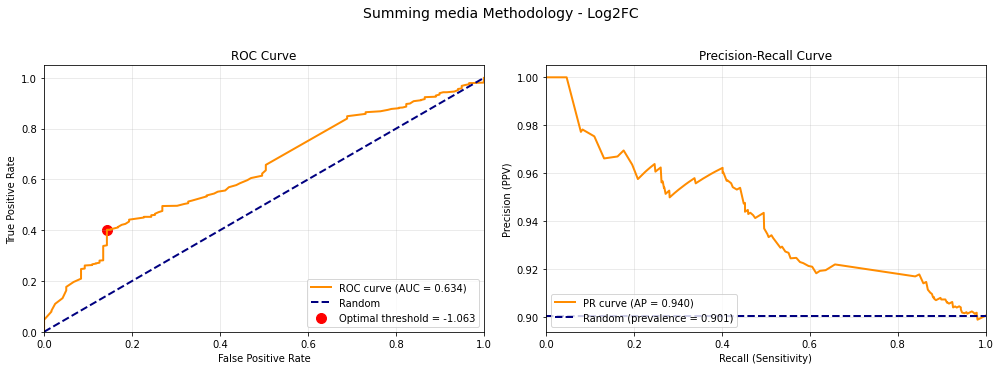


Classification Performance: Summing media Methodology - Log2FC
Dataset: 1199 edges (1080 pathogenic, 119 benign)

Area Under ROC Curve (AUROC): 0.6338
Area Under PR Curve (AUPRC):  0.9399

Optimal Threshold (Youden): -1.0630

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4019
  Specificity:           0.8571
  Precision (PPV):       0.9623
  Negative Pred. Value:  0.1364
  Accuracy:              0.4470



{'auroc': 0.633765172735761,
 'auprc': 0.9399144007528688,
 'optimal_threshold': -1.0629946426704622,
 'sensitivity': 0.40185185185185185,
 'specificity': 0.8571428571428571,
 'precision': 0.9623059866962306,
 'npv': 0.13636363636363635,
 'accuracy': 0.4470391993327773,
 'n_variants': 1199,
 'n_pathogenic': 1080,
 'n_benign': 119,
 'fpr': array([0.        , 0.        , 0.        , 0.        , 0.        ,
        0.01680672, 0.01680672, 0.02521008, 0.04201681, 0.05042017,
        0.05042017, 0.06722689, 0.08403361, 0.08403361, 0.08403361,
        0.08403361, 0.08403361, 0.08403361, 0.08403361, 0.08403361,
        0.08403361, 0.09243697, 0.09243697, 0.09243697, 0.09243697,
        0.1092437 , 0.1092437 , 0.11764706, 0.11764706, 0.12605042,
        0.12605042, 0.12605042, 0.13445378, 0.13445378, 0.13445378,
        0.13445378, 0.13445378, 0.13445378, 0.13445378, 0.13445378,
        0.13445378, 0.13445378, 0.13445378, 0.13445378, 0.13445378,
        0.13445378, 0.13445378, 0.13445378, 0.13

In [24]:
from sklearn.metrics import roc_curve, auc, precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt
import seaborn as sns

def evaluate_classification_performance(scores_df, metric_col, title=None, filter_edges=None, verbose=False, show_plots=True):
    """
    Calculate AUROC and Precision-Recall metrics for benign vs pathogenic classification.
    
    Parameters:
    -----------
    scores_df : polars.DataFrame
        DataFrame containing scores and clinical significance
    metric_col : str
        Name of the column containing the metric to evaluate (e.g., 'log2fc')
    title : str, optional
        Title for the plots
    filter_edges : int, optional
        Minimum number of edges required to include a variant
    
    Returns:
    --------
    dict : Dictionary containing AUROC, AUPRC, and other metrics
    """
    
    # Convert to pandas for sklearn compatibility
    scores_pd = scores_df.to_pandas()
    
    # Filter by number of edges if specified
    if filter_edges is not None and 'num_edges' in scores_pd.columns:
        scores_pd = scores_pd[scores_pd['num_edges'] >= filter_edges]
    
    # Filter to only benign and pathogenic
    filtered = scores_pd[scores_pd['clinvar_clnsig_clean'].isin(['1_Pathogenic', '2_Benign'])].copy()
    
    # Remove NaN values in metric column
    filtered = filtered[filtered[metric_col].notna()]
    
    if len(filtered) < 10:
        print(f"Warning: Only {len(filtered)} variants available for evaluation")
        return None
    
    # Create binary labels (1 = Pathogenic, 0 = Benign)
    y_true = (filtered['clinvar_clnsig_clean'] == '1_Pathogenic').astype(int)
    y_scores = filtered[metric_col].values
    
    # For log2fc, more negative = more pathogenic, so we negate for ROC
    # Adjust this based on your metric interpretation
    y_scores_roc = -y_scores  # Negative log2fc indicates loss of function (pathogenic)
    
    # Calculate ROC curve and AUROC
    fpr, tpr, roc_thresholds = roc_curve(y_true, y_scores_roc)
    roc_auc = auc(fpr, tpr)
    
    # Calculate Precision-Recall curve and AUPRC
    precision, recall, pr_thresholds = precision_recall_curve(y_true, y_scores_roc)
    auprc = average_precision_score(y_true, y_scores_roc)
    
    # Calculate optimal threshold (Youden's index for ROC)
    optimal_idx = np.argmax(tpr - fpr)
    optimal_threshold_roc = -roc_thresholds[optimal_idx]  # Convert back to original scale
    
    if show_plots:    
        # Create plots
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        
        # ROC Curve
        axes[0].plot(fpr, tpr, color='darkorange', lw=2, 
                    label=f'ROC curve (AUC = {roc_auc:.3f})')
        axes[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random')
        axes[0].scatter(fpr[optimal_idx], tpr[optimal_idx], marker='o', color='red', 
                        s=100, label=f'Optimal threshold = {optimal_threshold_roc:.3f}')
        axes[0].set_xlim([0.0, 1.0])
        axes[0].set_ylim([0.0, 1.05])
        axes[0].set_xlabel('False Positive Rate')
        axes[0].set_ylabel('True Positive Rate')
        axes[0].set_title('ROC Curve')
        axes[0].legend(loc="lower right")
        axes[0].grid(alpha=0.3)
        
        # Precision-Recall Curve
        axes[1].plot(recall, precision, color='darkorange', lw=2,
                    label=f'PR curve (AP = {auprc:.3f})')
        axes[1].axhline(y=y_true.mean(), color='navy', linestyle='--', lw=2,
                        label=f'Random (prevalence = {y_true.mean():.3f})')
        axes[1].set_xlim([0.0, 1.0])
        # axes[1].set_ylim([0.0, 1.05])
        axes[1].set_xlabel('Recall (Sensitivity)')
        axes[1].set_ylabel('Precision (PPV)')
        axes[1].set_title('Precision-Recall Curve')
        axes[1].legend(loc="lower left")
        axes[1].grid(alpha=0.3)
        
        if title:
            fig.suptitle(title, fontsize=14, y=1.02)
        
        plt.tight_layout()
        plt.show()
    
    # Calculate additional metrics at optimal threshold
    y_pred_optimal = (y_scores_roc >= roc_thresholds[optimal_idx]).astype(int)
    
    tp = np.sum((y_pred_optimal == 1) & (y_true == 1))
    fp = np.sum((y_pred_optimal == 1) & (y_true == 0))
    tn = np.sum((y_pred_optimal == 0) & (y_true == 0))
    fn = np.sum((y_pred_optimal == 0) & (y_true == 1))
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    ppv = tp / (tp + fp) if (tp + fp) > 0 else 0
    npv = tn / (tn + fn) if (tn + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    # Print summary
    if verbose:
        print(f"\n{'='*60}")
        print(f"Classification Performance: {title if title else metric_col}")
        print(f"{'='*60}")
        print(f"Dataset: {len(filtered)} edges ({y_true.sum()} pathogenic, {len(y_true) - y_true.sum()} benign)")
        print(f"\nArea Under ROC Curve (AUROC): {roc_auc:.4f}")
        print(f"Area Under PR Curve (AUPRC):  {auprc:.4f}")
        print(f"\nOptimal Threshold (Youden): {optimal_threshold_roc:.4f}")
        print(f"\nPerformance at Optimal Threshold:")
        print(f"  Sensitivity (Recall):  {sensitivity:.4f}")
        print(f"  Specificity:           {specificity:.4f}")
        print(f"  Precision (PPV):       {ppv:.4f}")
        print(f"  Negative Pred. Value:  {npv:.4f}")
        print(f"  Accuracy:              {accuracy:.4f}")
        print(f"{'='*60}\n")
    
    # Return metrics dictionary
    return {
        'auroc': roc_auc,
        'auprc': auprc,
        'optimal_threshold': optimal_threshold_roc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': ppv,
        'npv': npv,
        'accuracy': accuracy,
        'n_variants': len(filtered),
        'n_pathogenic': y_true.sum(),
        'n_benign': len(y_true) - y_true.sum(),
        'fpr': fpr,
        'tpr': tpr,
        'roc_thresholds': roc_thresholds,
        'precision_curve': precision,
        'recall_curve': recall,
        'pr_thresholds': pr_thresholds
    }


# 3. Benign growth methodology (with WT fallback)
print("\n" + "="*80)
print("APPROACH 3: Media filtered by benign growth (WT fallback)")
print("="*80)
evaluate_classification_performance(
    normalized_scores.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc_standard',
    title='Summing media Methodology - Log2FC',
    verbose=True
)


In [25]:
normalized_scores

ad_orf_id,db_orf_id,db_mut_id,retest_batch,normalized_score,normalized_score_best_media,best_media,assay_id,wt_normalized_score,wt_normalized_score_best_media,log2fc_standard,log2fc_best_media,ad_symbol,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,i64,str,f64,f64,str,str,f64,f64,f64,f64,str,str,str,str,str,str,str,f64,f64,str
100010307,6983,216125,"""VUSAPWT1B2""",0.0625,0.0,"""LWH1""","""1""",0.5625,0.75,-4.570278,-12.872867,"""DYNLT1""","""PITX2""","""Arg144Pro""","""431G>C""","""ENSG00000164093""","""CEGS2""","""1_Pathogenic""",null,2.0,"""PITX2_Arg144Pro"""
70334,9905,0,"""VUSAPWT6B1""",0.5,0.75,"""LWH10""","""6""",0.5,0.75,0.0,0.0,"""SFT2D1""","""PNKP""",null,null,"""ENSG00000039650""",null,null,null,null,"""PNKP"""
100067220,2455,200621,"""VUSAPWT1B2""",0.6875,1.0,"""LWH1""","""1""",0.4375,1.0,0.940575,0.0,"""PRKAR1B""","""PRKAR1A""","""Arg335Pro""","""1004G>C""","""ENSG00000108946""","""CEGS2""","""1_Pathogenic""",null,null,"""PRKAR1A_Arg335Pro"""
100011278,4870,215272,"""VUSAPWT1B2""",0.75,0.75,"""LWA""","""1""",0.875,1.0,-0.320805,-0.414989,"""KRT16""","""KRT6A""","""Leu170Phe""","""508C>T""","""ENSG00000205420""","""CEGS2""","""1_Pathogenic""",null,1.0,"""KRT6A_Leu170Phe"""
12334,14879,0,"""VUSAPWT1B2""",0.5625,0.75,"""LWH1""","""1""",0.5625,0.75,0.0,0.0,"""SSBP3""","""SS18L1""",null,null,"""ENSG00000184402""",null,null,null,null,"""SS18L1"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
100070143,13320,204012,"""VUSAPWT1B2""",0.75,0.75,"""LWH10""","""1""",0.5625,0.75,0.59868,0.0,"""HSF2BP""","""VHL""","""Arg126Gly""","""376C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",null,2.0,"""VHL_Arg126Gly"""
100067112,888,200363,"""VUSAPWT1B2""",0.0,0.0,"""LWH25""","""1""",0.875,1.0,-18.892427,-13.287857,"""MCC""","""PCCA""","""Met348Lys""","""1043T>A""","""ENSG00000175198""","""CEGS2""","""1_Pathogenic""",0.000003,2.0,"""PCCA_Met348Lys"""
8297,13796,218155,"""VUSAPWT1B2""",0.375,0.5,"""LWH25""","""1""",0.625,0.75,-1.062995,-0.584866,"""HBZ""","""HBD""","""His147Arg""","""440A>G""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_His147Arg"""


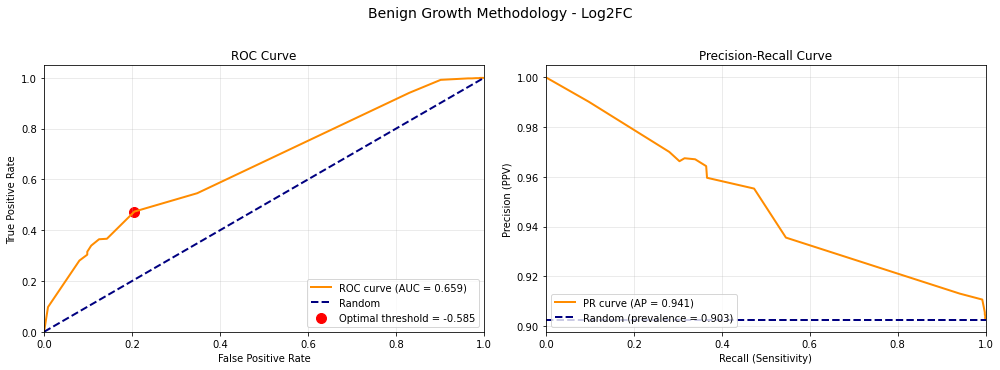


Classification Performance: Benign Growth Methodology - Log2FC
Dataset: 1149 edges (1037 pathogenic, 112 benign)

Area Under ROC Curve (AUROC): 0.6593
Area Under PR Curve (AUPRC):  0.9415

Optimal Threshold (Youden): -0.5849

Performance at Optimal Threshold:
  Sensitivity (Recall):  0.4735
  Specificity:           0.7946
  Precision (PPV):       0.9553
  Negative Pred. Value:  0.1402
  Accuracy:              0.5048



{'auroc': 0.6593366854938696,
 'auprc': 0.9414740990140816,
 'optimal_threshold': -0.5848663370790017,
 'sensitivity': 0.4734811957569913,
 'specificity': 0.7946428571428571,
 'precision': 0.9552529182879378,
 'npv': 0.14015748031496064,
 'accuracy': 0.504786771105309,
 'n_variants': 1149,
 'n_pathogenic': 1037,
 'n_benign': 112,
 'fpr': array([0.        , 0.00892857, 0.08035714, 0.09821429, 0.09821429,
        0.10714286, 0.125     , 0.14285714, 0.20535714, 0.34821429,
        0.83035714, 0.90178571, 0.96428571, 0.97321429, 0.98214286,
        0.99107143, 0.99107143, 1.        ]),
 'tpr': array([0.        , 0.09739634, 0.28061716, 0.30376085, 0.31533269,
        0.33944069, 0.36451302, 0.36644166, 0.4734812 , 0.54580521,
        0.94117647, 0.99228544, 0.99807136, 0.99807136, 0.99903568,
        0.99903568, 1.        , 1.        ]),
 'roc_thresholds': array([         inf,  13.28785664,  12.87286723,  12.28800089,
          1.9995673 ,   1.58457788,   0.99985575,   0.99971155,
        

In [26]:
evaluate_classification_performance(
    normalized_scores.filter(pl.col("db_mut_id") != 0),
    metric_col='log2fc_best_media',
    title='Benign Growth Methodology - Log2FC',
    verbose=True
)

In [27]:
scores = pl.read_csv(f"{outputs_dir}/4_normalized_consensus_scores.csv")

# keep only scores where there is at least one matched reference-variant set
orfs_with_alleles = scores.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = scores.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
scores = scores.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = scores.select("db_orf_id").to_series().unique().to_list()

# print(scores)

In [28]:
# Create orf_profiles for each profiled gene

orf_profiles = {}
shape_summary = []
for gene in genes:
    gene_scores = scores.filter(pl.col("db_orf_id") == gene)
    profile = gene_scores.pivot(
                values="normalized_score",
                index="ad_orf_id",
                on="db_mut_id"
            )
    orf_profiles[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

    # profile.write_csv(f"{outputs_dir}/edgotype_orf_profiles/orf_id_{gene}.csv")

shape_summary = pl.DataFrame(shape_summary)

In [29]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate Euclidean distance for each variant relative to it's wildtype reference

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for orf in orf_profiles:
    profiles = orf_profiles[orf]
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])

    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        # # Cosine similarity
        # wt = profiles_filled.select(zero_col).to_numpy()
        # var = profiles_filled.select(col).to_numpy()

        # if wt.ndim == 1:
        #     wt = wt.reshape(-1, 1)
        # if var.ndim == 1:
        #     var = var.reshape(-1, 1)
        # cos_sim = cosine_similarity(wt.T, var.T)
        # cos_dist = 1 - cos_sim

        # # calculate frac perturbed
        # wt_pass = []
        # per_edges = []
        # for thresh in wt_thresh:
        #     filt_wt = profiles.filter(pl.col("0") > thresh)
        #     wt_pass.append(filt_wt.shape[0])
        #     per_edges.append(filt_wt.filter((pl.col(col)/pl.col("0")) <= perturbed_thresh).shape[0])            

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            # "cosine_distance": cos_dist,
            "num_edges": profiles.shape[0],
            # "num_zero_wt": profiles.filter(pl.col("0") == 0).shape[0],
            # "num_per_0.0": per_edges[0],
            # "num_per_0.1": per_edges[1],
            # "num_per_0.2": per_edges[2],
            # "num_per_0.3": per_edges[3],
            # "num_per_0.4": per_edges[4],
            # "num_per_0.5": per_edges[5],
            # "num_edge_0.0": wt_pass[0],
            # "num_edge_0.1": wt_pass[1],
            # "num_edge_0.2": wt_pass[2],
            # "num_edge_0.3": wt_pass[3],
            # "num_edge_0.4": wt_pass[4],
            # "num_edge_0.5": wt_pass[5],
            # "frac_per_0.0": per_edges[0]/wt_pass[0] if wt_pass[0] != 0 else None,
            # "frac_per_0.1": per_edges[1]/wt_pass[1] if wt_pass[1] != 0 else None,
            # "frac_per_0.2": per_edges[2]/wt_pass[2] if wt_pass[2] != 0 else None,
            # "frac_per_0.3": per_edges[3]/wt_pass[3] if wt_pass[3] != 0 else None,
            # "frac_per_0.4": per_edges[4]/wt_pass[4] if wt_pass[4] != 0 else None,
            # "frac_per_0.5": per_edges[5]/wt_pass[5] if wt_pass[5] != 0 else None
        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances = pl.concat(orf_distances, how="vertical_relaxed")
orf_distances = orf_distances.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances = orf_distances.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
# orf_distances.write_csv(f"{outputs_dir}/5_variant_perturbation_scores.csv")

orf_distances = orf_distances.with_columns(
    pl.col("db_mut_id").cast(pl.Int64).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.Int64).alias("db_orf_id")
)

orf_distances = orf_distances.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances


db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
i64,i64,f64,i64,f64,str,str,str,str,str,str,f64,f64,str
2803,200947,0.25,1,0.25,"""HMBS""","""Asp359Asn""","""1075G>A""","""ENSG00000256269""","""CEGS2""","""2_Benign""",0.000065,2.0,"""HMBS_Asp359Asn"""
13796,218148,0.257694,2,0.182217,"""HBD""","""Arg105Ser""","""315G>T""","""ENSG00000223609""","""CEGS2""","""5_Others""",null,null,"""HBD_Arg105Ser"""
70497,3848,0.1875,1,0.1875,"""AGXT""","""Ala210Pro""","""628G>C""","""ENSG00000172482""","""Edgotyping3""","""1_Pathogenic""",null,null,"""AGXT_Ala210Pro"""
11805,2144,0.75519,2,0.534,"""SMAD3""","""Met255Arg""","""764T>G""","""ENSG00000166949""","""Edgotyping3""","""4_VUS""",null,1.0,"""SMAD3_Met255Arg"""
2803,200934,0.125,1,0.125,"""HMBS""","""Leu177Arg""","""530T>G""","""ENSG00000256269""","""CEGS2""","""1_Pathogenic""",null,1.0,"""HMBS_Leu177Arg"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
145,200059,0.0625,1,0.0625,"""PTS""","""Arg25Gln""","""74G>A""","""ENSG00000150787""","""CEGS2""","""1_Pathogenic""",6.9900e-7,2.0,"""PTS_Arg25Gln"""
13320,204006,0.125,1,0.125,"""VHL""","""His150Asp""","""448C>G""","""ENSG00000134086""","""CEGS2""","""1_Pathogenic""",6.8405e-7,1.0,"""VHL_His150Asp"""
7982,202803,0.0625,2,0.044194,"""HPRT1""","""Thr168Ile""","""503C>T""","""ENSG00000165704""","""CEGS2""","""1_Pathogenic""",null,null,"""HPRT1_Thr168Ile"""


In [30]:
normalized_scores_pd = normalized_scores.to_pandas()
normalized_scores_pd['ppi_group'] = normalized_scores_pd['ad_orf_id'].astype(str) + "_" + normalized_scores_pd['db_orf_id'].astype(str) + "_" + normalized_scores_pd['db_mut_id'].astype(str)
normalized_scores_pd['edge_group'] = normalized_scores_pd['ad_orf_id'].astype(str) + "_" + normalized_scores_pd['db_orf_id'].astype(str)
print(normalized_scores_pd.ppi_group.nunique())
print(normalized_scores_pd.edge_group.nunique())
print(normalized_scores_pd.db_orf_id.nunique())

3122
957
207


In [31]:
# Filter to keep only genes that have at least one allele tested and reference WT measurement

normalized_scores_pl = pl.DataFrame(normalized_scores_pd)

orfs_with_alleles = normalized_scores_pl.filter(pl.col("db_mut_id") != 0).select("db_orf_id").unique().to_series().to_list()
orfs = normalized_scores_pl.filter(pl.col("db_mut_id") == 0).select("db_orf_id").unique().to_series().to_list()

complete_orf_pairs = [i for i in orfs if i in orfs_with_alleles]
normalized_scores_pl = normalized_scores_pl.filter(pl.col("db_orf_id").is_in(complete_orf_pairs))
genes = normalized_scores_pl.select("db_orf_id").to_series().unique().to_list()

# Since scores were summed across conditions, there should be only one entry per ad_orf_id, db_orf_id, db_mut_id, retest_batch combination

normalized_scores_pl = normalized_scores_pl.unique(subset=["ad_orf_id", "db_orf_id", "db_mut_id", "retest_batch"])
normalized_scores_pl.write_csv('./tmp/normalized_scores_pl_log2fc.csv')


In [32]:
normalized_scores_pd = normalized_scores_pl.to_pandas()

print(normalized_scores_pd.ppi_group.nunique())
print(normalized_scores_pd.edge_group.nunique())
print(normalized_scores_pd.db_orf_id.nunique())

2455
325
75


In [33]:
# Create orf_profiles for each profiled gene

orf_profiles_best = {}

score_filtered = normalized_scores.filter(~pl.col("normalized_score_best_media").is_null())

shape_summary = []
for gene in genes:
    gene_scores = score_filtered.filter(pl.col("db_orf_id") == gene)
    # gene_scores = normalized_scores.filter(pl.col("db_orf_id") == gene)
    # gene_scores = gene_scores.filter(~pl.col("normalized_score_best_media").is_null())
    
    profile = gene_scores.pivot(
                values="normalized_score_best_media",
                index="ad_orf_id",
                on="db_mut_id"
            )
    
    if profile.shape[1] > 1:  # only keep profiles with at least one variant
        
        orf_profiles_best[gene] = profile

    shape_summary.append({
        "gene": gene,
        "n_interactors": profile.height,
        "n_alleles": profile.width
    })

    # profile.write_csv(f"{outputs_dir}/edgotype_orf_profiles/orf_id_{gene}.csv")

shape_summary = pl.DataFrame(shape_summary)

In [34]:
from sklearn.metrics.pairwise import cosine_similarity

# Calculate Euclidean distance for each variant relative to it's wildtype reference

zero_col = "0"
perturbed_thresh = 0.5 # edge called "perturbed" if >= 50% decrease compared to wt reference
orf_distances_best = []

wt_thresh = [0, 0.1, 0.2, 0.3, 0.4, 0.5]

for orf in orf_profiles_best:
    # print(orf)
    profiles = orf_profiles_best[orf]
    
    # filter out edges where the WT could not be measured
    profiles = profiles.filter(~pl.col("0").is_null())

    db_orf_id = orf

    columns = [col for col in profiles.columns if col != "ad_orf_id"]

    # "impute" missing values as the mean for that variant
    profiles_filled = profiles.with_columns([
        pl.when(pl.col(col).is_null())
        .then(pl.col(col).mean())
        .otherwise(pl.col(col))
        .alias(col)
        for col in columns
    ])

    # compute distances
    distance_rows = []
    for col in columns:
        if col == zero_col:
            continue
        
        # Euclidean distance
        diff_squared = (profiles_filled[col] - profiles_filled[zero_col]) ** 2
        distances = np.sqrt(diff_squared.sum())

        distance_rows.append({
            "db_orf_id": db_orf_id,
            "db_mut_id": int(col),
            "euclid_distance": distances,
            "num_edges": profiles.shape[0],

        })


    result_profiles = pl.DataFrame(distance_rows)
    orf_distances_best.append(result_profiles)

# concatentate and normalize wrt dimensionality
orf_distances_best = pl.concat(orf_distances_best, how="vertical_relaxed")
orf_distances_best = orf_distances_best.with_columns(
    (pl.col("euclid_distance") / pl.col("num_edges").cast(pl.Float64).sqrt()).alias("normalized_euclid_distance"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id"),
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
)

# append metadata and write out scores
metadata = pl.read_csv(f"{meta_outputs}/slim_metadata.csv").rename({
    "orf_id": "db_orf_id",
    "mut_id": "db_mut_id"
}).with_columns(
    pl.col("db_orf_id").cast(pl.String).alias("db_orf_id"),
    pl.col("db_mut_id").cast(pl.String).alias("db_mut_id")
)

orf_distances_best = orf_distances_best.join(metadata, on=["db_orf_id", "db_mut_id"], how="left")
# orf_distances.write_csv(f"{outputs_dir}/5_variant_perturbation_scores.csv")

orf_distances_best = orf_distances_best.sort("db_mut_id", descending=True).unique(subset=["allele_0"], keep="first")
orf_distances_best


db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
str,str,f64,i64,f64,str,str,str,str,str,str,f64,f64,str
"""281""","""744""",0.25,1,0.25,"""MVK""","""Asn205Asp""","""613A>G""","""ENSG00000110921""","""RC4""","""1_Pathogenic""",0.000027,2.0,"""MVK_Asn205Asp"""
"""4870""","""215276""",0.433013,4,0.216506,"""KRT6A""","""Arg164Pro""","""491G>C""","""ENSG00000205420""","""CEGS2""","""5_Others""",null,null,"""KRT6A_Arg164Pro"""
"""7167""","""12744""",0.75,1,0.75,"""AIPL1""","""Met79Thr""","""236T>C""","""ENSG00000129221""","""RC4""","""5_Others""",null,null,"""AIPL1_Met79Thr"""
"""7675""","""202588""",1.457738,3,0.841625,"""NMNAT1""","""Arg237Leu""","""710G>T""","""ENSG00000173614""","""CEGS2""","""1_Pathogenic""",null,null,"""NMNAT1_Arg237Leu"""
"""4723""","""201749""",0.0,2,0.0,"""TPM1""","""Ala277Val""","""830C>T""","""ENSG00000140416""","""CEGS2""","""4_VUS""",null,1.0,"""TPM1_Ala277Val"""
…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""2713""","""1005""",3.5,19,0.802955,"""MLH1""","""Gln701His""","""2103G>C""","""ENSG00000076242""","""Edgotyping3""","""1_Pathogenic""",null,3.0,"""MLH1_Gln701His"""
"""8999""","""202977""",0.25,1,0.25,"""TTR""","""Phe64Leu""","""190T>C""","""ENSG00000118271""","""CEGS2""","""3_Conflicting""",0.000014,1.0,"""TTR_Phe64Leu"""
"""513""","""213754""",0.25,3,0.144338,"""FA2H""","""Phe144Ser""","""431T>C""","""ENSG00000103089""","""CEGS2""","""1_Pathogenic""",null,null,"""FA2H_Phe144Ser"""


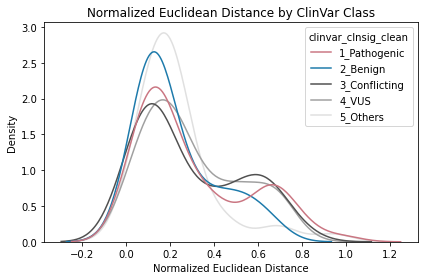

In [35]:

variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

sns.kdeplot(
    data=orf_distances,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

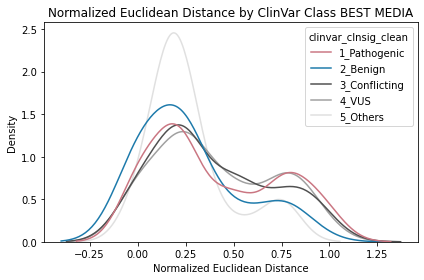

In [36]:

variables = ["normalized_euclid_distance", "frac_per_0.0", "frac_per_0.2", "cosine_distance"]

# Define color mapping for classes
color_map = {
    "1_Pathogenic": "red",
    "2_Benign": "green",
    "3_Conflicting": "orange",
    "4_VUS": "blue"
}

# Only plot the first variable
var = variables[0]
hue_order = ["1_Pathogenic", "2_Benign", "3_Conflicting", "4_VUS", "5_Others"]

sns.kdeplot(
    data=orf_distances_best,
    x=var,
    hue="clinvar_clnsig_clean",
    hue_order=hue_order,
    # palette=[color_map.get(k, "gray") for k in hue_order],
    palette=palette_dict['clinvar_clnsig_clean'],
    common_norm=False
)

plt.title('Normalized Euclidean Distance by ClinVar Class BEST MEDIA')
plt.xlabel('Normalized Euclidean Distance')
plt.tight_layout()
plt.show()

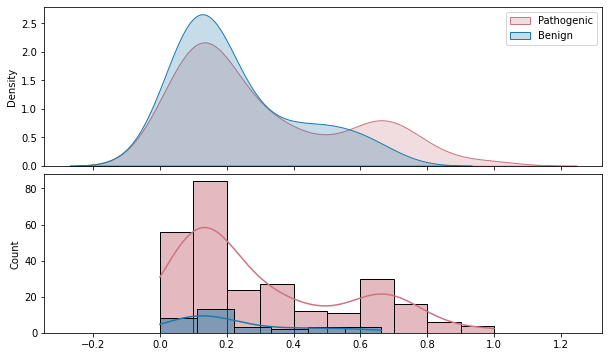

In [37]:

path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=orf_distances.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=orf_distances.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(orf_distances.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(orf_distances.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

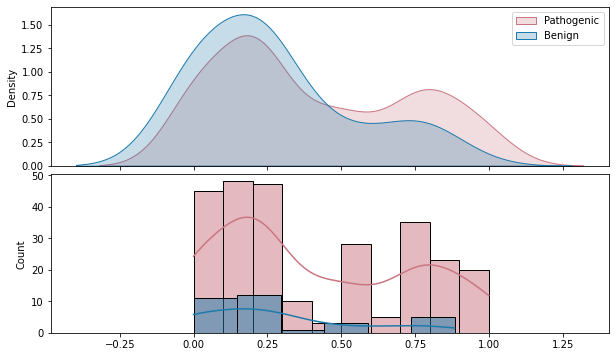

In [38]:
path_thres = 0.42

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
sns.kdeplot(data=orf_distances_best.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], fill=True, ax=axes[0])
sns.kdeplot(data=orf_distances_best.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], fill=True, ax=axes[0])
# axes[0].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
axes[0].legend()

sns.histplot(orf_distances_best.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")["normalized_euclid_distance"].to_numpy(), label='Pathogenic', color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], kde=True, ax=axes[1])
sns.histplot(orf_distances_best.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")["normalized_euclid_distance"].to_numpy(), label='Benign', color=palette_dict["clinvar_clnsig_clean"]["2_Benign"], kde=True, ax=axes[1])
# axes[1].axvline(x=path_thres, color=palette_dict["clinvar_clnsig_clean"]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
plt.subplots_adjust(hspace=.05)
plt.show()

In [39]:

orf_distances.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_manual_referenceSet.csv")

orf_distances.with_columns(
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_manual_allScores.csv")

In [40]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-05_11:51:27 INFO: Reading input 
2025-11-05_11:51:28 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-11-05_11:51:34 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-11-05_11:51:53 INFO: Reading input 
2025-11-05_11:51:53 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-11-05_11:51:54 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


CalledProcessError: Command 'b'source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh\nconda activate py310\n\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_bcv.log" --bandwidth "bcv" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_allScores.csv ../3_outputs/sqY2H/PPI_manual_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_LLR_default.log" 

In [ ]:
LLR_threshold = 0.657

# plot summed

Plotting normalized_euclid_distance distribution for Pathogenic and Benign variants
Total variants: 535
Total unique db_orf_id: 76
Total Pathogenic variants: 272
Total Benign variants: 32
fixed_threshold: 0.657


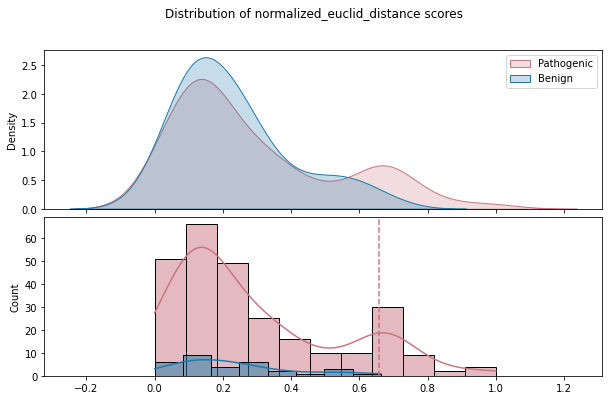

Benign: 1 (3.12%)
Pathogenic: 42 (15.44%)
VUS: 13 (13.13%)
Conflicting: 11 (12.94%)


In [ ]:
def plot_patho_benign(scores=None, metric="normalized_euclid_distance", num_edge_filter=1, title=None, threshold=None, fixed_threshold=None, log_treshold=False):
    
    palette_str = "clinvar_clnsig_clean"
    
    palette_dict = {
        "clinvar_clnsig_clean":{
            '1_Pathogenic': "#CA7682",
            '2_Benign': "#1D7AAB",
            '3_Conflicting': "#505050", #"grey", or lighter red "#E6B1B8"
            '4_VUS': "#A0A0A0", ## Pillar default
            '5_Others': "#E0E0E0"
            # '6_No_ClinVar'
        }
    }
    

    if scores is None:
        scores = orf_distances  # This will use the current state of orf_distances
        
    print(f"Plotting {metric} distribution for Pathogenic and Benign variants")
    # total number of variants
    print("Total variants:", scores.shape[0])
    # total number of db_orf_ids
    print("Total unique db_orf_id:", scores.select(pl.col("db_orf_id").n_unique()).item())
    # total number of pathogenic variants
    print("Total Pathogenic variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic").shape[0])
    # total number of benign variants
    print("Total Benign variants:", scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign").shape[0])
    
    
        
    if threshold:    
        path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].max() + 0.016
        print('path_thres:', path_thres)
        if log_treshold:
            path_thres = scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].min() - 0.016
            print('path_thres:', path_thres)
        elif type(threshold) == float or type(threshold) == int:
            path_thres = threshold
            print('path_thres:', path_thres)
        
    if fixed_threshold:
        path_thres = fixed_threshold
        print('fixed_threshold:', path_thres)

    fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], fill=True, ax=axes[0])
    sns.kdeplot(data=scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], fill=True, ax=axes[0])
    if threshold:
        axes[0].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    axes[0].legend()

    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")[metric].to_numpy(), label='Pathogenic', color=palette_dict[palette_str]["1_Pathogenic"], kde=True, ax=axes[1])
    sns.histplot(scores.filter(pl.col("clinvar_clnsig_clean")=="2_Benign")[metric].to_numpy(), label='Benign', color=palette_dict[palette_str]["2_Benign"], kde=True, ax=axes[1])
    if threshold or fixed_threshold:
        axes[1].axvline(x=path_thres, color=palette_dict[palette_str]["1_Pathogenic"], linestyle='--', label='Pathogenic Thres.')
    plt.subplots_adjust(hspace=.05)
    if title is not None:
        plt.suptitle(title)
    else:
        plt.suptitle(f"Distribution of {metric} scores")
    plt.show()
    
    if num_edge_filter > 1:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign").filter(pl.col("num_edges") >= num_edge_filter)
        # print(benign_scores.shape)

        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic").filter(pl.col("num_edges") >= num_edge_filter)
        # print(path_scores.shape)

        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS").filter(pl.col("num_edges") >= num_edge_filter)
        # print(vus_scores.shape)

        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting").filter(pl.col("num_edges") >= num_edge_filter)
        # print(conf_scores.shape)
    else:
        benign_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "2_Benign")
        path_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "1_Pathogenic")
        vus_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "4_VUS")
        conf_scores = scores.filter(pl.col("clinvar_clnsig_clean") == "3_Conflicting")
    if threshold or fixed_threshold:
        if log_treshold:
            print(f"Benign: {benign_scores.filter(pl.col(metric) < path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) < path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) < path_thres).shape[0]} ({path_scores.filter(pl.col(metric) < path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) < path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) < path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) < path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) < path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
        else:
            print(f"Benign: {benign_scores.filter(pl.col(metric) > path_thres).shape[0]} ({benign_scores.filter(pl.col(metric) > path_thres).shape[0] / benign_scores.shape[0] * 100:.2f}%)")
            print(f"Pathogenic: {path_scores.filter(pl.col(metric) > path_thres).shape[0]} ({path_scores.filter(pl.col(metric) > path_thres).shape[0] / path_scores.shape[0] * 100:.2f}%)")
            print(f"VUS: {vus_scores.filter(pl.col(metric) > path_thres).shape[0]} ({vus_scores.filter(pl.col(metric) > path_thres).shape[0] / vus_scores.shape[0] * 100:.2f}%)")
            print(f"Conflicting: {conf_scores.filter(pl.col(metric) > path_thres).shape[0]} ({conf_scores.filter(pl.col(metric) > path_thres).shape[0] / conf_scores.shape[0] * 100:.2f}%)")
            


plot_patho_benign(scores=orf_distances, metric="normalized_euclid_distance", fixed_threshold=LLR_threshold)

# LLR best media

In [ ]:

orf_distances_best.filter(
    pl.col("clinvar_clnsig_clean").is_in(["1_Pathogenic", "2_Benign"])
).with_columns(
    pl.when(pl.col("clinvar_clnsig_clean")=="1_Pathogenic")
    .then(pl.lit("Positive"))
    .otherwise(pl.lit("Negative"))
    .alias("referenceSet"),
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvsp")
).select(
    pl.col(["hgvsp", "score", "referenceSet", "normalized_euclid_distance", "allele_0", "clinvar_clnsig_clean"])
).write_csv("../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv")

orf_distances_best.with_columns(
    pl.col("normalized_euclid_distance").alias("score"),
    pl.col("allele_0").alias("hgvs_pro")
).select(pl.col(["hgvs_pro", "score"])).write_csv("../3_outputs/sqY2H/PPI_manual_Best_allScores.csv")

In [ ]:
%%bash
source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh
conda activate py310

Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_bcv.log" --bandwidth "bcv" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_default" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_default.log" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_nrd" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_nrd.log" --bandwidth "nrd" --printTransitions
Rscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_sj" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_sj.log" --printTransitions --bandwidth "SJ"

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-31_10:41:53 INFO: Reading input 
2025-10-31_10:41:53 INFO: Calculating densties 


Warning messages:
1: In stats::bw.bcv(data) : minimum occurred at one end of the range
2: In stats::bw.bcv(data) : minimum occurred at one end of the range


2025-10-31_10:41:54 INFO: Drawing LLR plot 
2025-10-31_10:41:54 INFO: Drawing PRC curve 
  |======================================================================| 100%2025-10-31_10:41:55 INFO: Category transitions:  
0.801 : none -> patho.support
2025-10-31_10:41:55 INFO: Bootstrapping confidence intervals at  10000  iterations 
2025-10-31_10:41:55 INFO: Writing output to file  ../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_bcv.csv 
2025-10-31_10:41:55 INFO: Done! 


Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


...

Loading required package: parallel
Loading required package: maveLLR
Warning message:
NAs introduced by coercion 


2025-10-31_10:42:00 INFO: Reading input 
2025-10-31_10:42:00 INFO: Calculating densties 


Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>


2025-10-31_10:42:01 FATAL: Error in value[[3L]](cond) : 
  Normalization error: The function will not integrate.Two common causes are: 1.) The kernel is non-smooth, try a smooth kernel if possible. 2.) The supplied support is incorrect.
Calls: buildLLR.kernel ... tryCatch -> tryCatchList -> tryCatchOne -> <Anonymous>
 
  


CalledProcessError: Command 'b'source /opt/homebrew/Caskroom/miniconda/base/etc/profile.d/conda.sh\nconda activate py310\n\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_bcv" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_bcv.log" --bandwidth "bcv" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_nrd0" --logfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_nrd0.log" --bandwidth "nrd0" --printTransitions\nRscript ../../threshold_calibration/calcLLR.R ../3_outputs/sqY2H/PPI_manual_Best_allScores.csv ../3_outputs/sqY2H/PPI_manual_Best_referenceSet.csv --outfile "../3_outputs/sqY2H/calcLLR/PPI_manual_Best_LLR_score_default" --logfile "

In [ ]:
LLR_threshold = 0.801

# plot best

Plotting normalized_euclid_distance distribution for Pathogenic and Benign variants
Total variants: 525
Total unique db_orf_id: 74
Total Pathogenic variants: 264
Total Benign variants: 32
fixed_threshold: 0.801


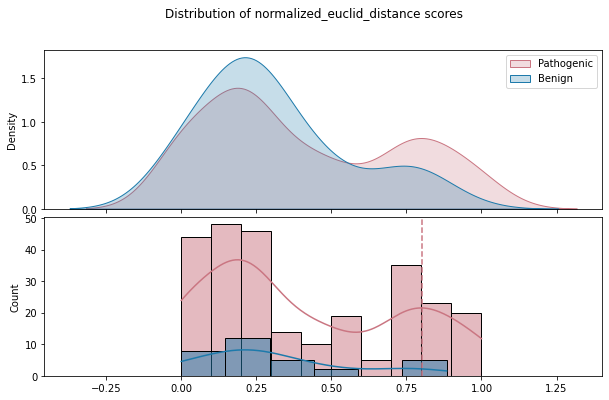

Benign: 1 (3.12%)
Pathogenic: 43 (16.29%)
VUS: 14 (14.14%)
Conflicting: 11 (13.25%)


In [ ]:
plot_patho_benign(scores=orf_distances_best, metric="normalized_euclid_distance", fixed_threshold=LLR_threshold)

In [ ]:
orf_distances_best.to_pandas()

,db_orf_id,db_mut_id,euclid_distance,num_edges,normalized_euclid_distance,symbol,aa_change,nt_change,ensembl_gene_id,collection,clinvar_clnsig_clean,gnomad_af,StarStatus,allele_0
0,4062,201432,1.660593,18,0.391406,PLP1,Val184Phe,550G>T,ENSG00000123560,CEGS2,1_Pathogenic,NaN,2.0,PLP1_Val184Phe
1,8143,202839,0.250000,2,0.176777,SH3BP2,Pro418His,1253C>A,ENSG00000087266,CEGS2,1_Pathogenic,6.963800e-07,1.0,SH3BP2_Pro418His
2,70497,205586,1.000000,7,0.377964,AGXT,Arg197Gln,590G>A,ENSG00000172482,CEGS2,2_Benign,4.572310e-03,2.0,AGXT_Arg197Gln
3,7652,1799,1.837117,5,0.821584,STXBP1,Leu183Pro,548T>C,ENSG00000136854,Edgotyping3,4_VUS,NaN,2.0,STXBP1_Leu183Pro
4,70497,3826,0.661438,7,0.250000,AGXT,Gly161Arg,481G>C,ENSG00000172482,Edgotyping3,1_Pathogenic,NaN,NaN,AGXT_Gly161Arg
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
520,70497,3805,1.118034,7,0.422577,AGXT,Ala85Asp,254C>A,ENSG00000172482,Edgotyping3,1_Pathogenic,NaN,NaN,AGXT_Ala85Asp
521,100016069,2660,1.250000,2,0.883883,KCNJ2,Pro420Leu,1259C>T,ENSG00000123700,Edgotyping3,3_Conflicting,2.325810e-05,1.0,KCNJ2_Pro420Leu
522,70497,205585,1.118034,7,0.422577,AGXT,Gly156Arg,466G>A,ENSG00000172482,Edgotyping3,1_Pathogenic,1.450080e-05,2.0,AGXT_Gly156Arg
523,71892,4020,0.750000,1,0.750000,TH,Pro121Leu,362C>T,ENSG00000180176,Edgotyping3,3_Conflicting,NaN,1.0,TH_Pro121Leu


In [ ]:
orf_distances_best.write_csv('./tmp/manual_bestmedia_perturbation_scores.csv')
orf_distances.write_csv('./tmp/manual_summed_perturbation_scores.csv')

# Exploring qa/qc, dropped alleles

In [ ]:
def describe_dict(df_dict):
    for assay_id in df_dict.keys():
        print(f"\tAssay ID: {assay_id}")
        n_db_orfs = len(df_dict[assay_id].keys())
        only_wt_count = 0
        db_list_wt = []
        n_wt = 0
        n_alleles = 0
        db_list_wt_with_var_wt = []
        db_list_wt_with_only_var = []
        ad_list = []
        
        for db_orf_id, db_mut_d in df_dict[assay_id].items():
            # if db_orf_id == 53798:
            #     print('53798')
            #     print(db_mut_d)
            
            if 0 in db_mut_d.keys():
                n_wt += 1
                n_alleles += len(db_mut_d.keys()) - 1
            else:
                n_alleles += len(db_mut_d.keys())
                
            if len(db_mut_d.keys()) == 1 and 0 in db_mut_d.keys():
                only_wt_count += 1
                db_list_wt.append(db_orf_id)
                
            if len(db_mut_d.keys()) > 1 and 0 in db_mut_d.keys():
                db_list_wt_with_var_wt.append(db_orf_id)
                
            if 0 not in db_mut_d.keys():
                db_list_wt_with_only_var.append(db_orf_id)
                
            ad_set = set()
            for db_mut_id, ad_orf_id_set in db_mut_d.items():
                for ad_orf_id in ad_orf_id_set:
                    ad_set.add(ad_orf_id)
                    
            ad_list.extend(list(ad_set))
            
            
        print(f"\t\tNumber of DB ORFs: {n_db_orfs}")        
        print(f"\t\tNumber of DB alleles: {n_alleles}")
        print(f"\t\tNumber of DB ORFs with WT: {n_wt}")
        print(f"\t\tNumber of DB ORFs with only WT: {only_wt_count}, {(only_wt_count/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with WT and alleles: {len(db_list_wt_with_var_wt)}, {(len(db_list_wt_with_var_wt)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of DB ORFs with only alleles: {len(db_list_wt_with_only_var)}, {(len(db_list_wt_with_only_var)/n_db_orfs)*100:.2f}%")
        print(f"\t\tNumber of AD ORFs: {len(ad_list)}")

        print(f"\t\tDB ORFs with only WT: {db_list_wt}")
        print(f"\t\tDB ORFs with WT and alleles: {db_list_wt_with_var_wt}")
        print(f"\t\tDB ORFs with only alleles: {db_list_wt_with_only_var}")
        print()

In [ ]:
def compare_dicts(dict1, dict2):
    assay_array = ["VUSAPWT1B1", "VUSAPWT1B2", "VUSAPWT2B1", "VUSAPWT6B1"]
    for assay in assay_array:
        print(f"\tAssay: {assay}")

        lost_alleles = 0
        lost_wt = 0
        lost_db_orfs = 0
        lost_ad_orfs = 0

        total_alleles = 0
        total_wt = 0
        total_db_orfs = 0
        total_ad_orfs = 0

        # Compute totals from dict1
        for db_orf_id, db_mut_id_d in dict1[assay].items():
            total_db_orfs += 1
            if 0 in db_mut_id_d:
                total_wt += 1
                total_alleles += len(db_mut_id_d) - 1  # exclude WT
            else:
                total_alleles += len(db_mut_id_d)
                
            ad_set = set()
                
            ad_set = {ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf}
            total_ad_orfs += len(ad_set)

        for db_orf_id, db_mut_id_d in dict2[assay].items():
            if db_orf_id in dict1[assay]:
                db_mut_id_d1 = dict1[assay][db_orf_id]
                db_mut_id_d2 = db_mut_id_d

                ad_set_1 = {ad for db_mut, ad_orf in db_mut_id_d1.items() for ad in ad_orf}
                ad_set_2 = {ad for db_mut, ad_orf in db_mut_id_d2.items() for ad in ad_orf}
                lost_ad_orfs += len(ad_set_1 - ad_set_2)

                lost_alleles += sum(1 for db_mut in db_mut_id_d1 if db_mut != 0 and db_mut not in db_mut_id_d2)

                if 0 in db_mut_id_d1 and 0 not in db_mut_id_d2:
                    lost_wt += 1

            else:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)

                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        for db_orf_id, db_mut_id_d in dict1[assay].items():
            if db_orf_id not in dict2[assay]:
                lost_db_orfs += 1
                if 0 in db_mut_id_d:
                    lost_wt += 1
                    lost_alleles += len(db_mut_id_d) - 1
                else:
                    lost_alleles += len(db_mut_id_d)
                lost_ad_orfs += len({ad for db_mut, ad_orf in db_mut_id_d.items() for ad in ad_orf})

        def pct(x, total):
            return f"{(x / total * 100):.1f}%" if total else "NA"

        print(f"\t\tLost DB ORFs: {lost_db_orfs} / {total_db_orfs} ({pct(lost_db_orfs, total_db_orfs)})")
        print(f"\t\tLost alleles: {lost_alleles} / {total_alleles} ({pct(lost_alleles, total_alleles)})")
        print(f"\t\tLost WT: {lost_wt} / {total_wt} ({pct(lost_wt, total_wt)})")
        print(f"\t\tLost AD ORFs: {lost_ad_orfs} / {total_ad_orfs} ({pct(lost_ad_orfs, total_ad_orfs)})")
        print()


In [ ]:
dicts = [dict_before_qc, dict_after_db_groups, dict_after_db_conditions ,dict_after_mating, dict_after_aa, dict_after_seq_1, dict_after_seq_2]

In [ ]:
print("Data filtering through QC/QA:")
print()
print()
print('Before QC:')
print()
describe_dict(dict_before_qc)
print()
print('Step 1: Remove all db groups with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_groups)
print()
print('Differences before QC and step 1:')
print()
compare_dicts(dict_before_qc, dict_after_db_groups)
print()
print('________________________________________________________________________________')
print('Step 2: Remove all db conditions with the same allele if there was an autoactivation mating failure')
print()
describe_dict(dict_after_db_conditions)
print()
print()
print('Differences between step 1 and step 2:')
print()
compare_dicts(dict_after_db_groups, dict_after_db_conditions)
print()
print('________________________________________________________________________________')
print('Step 3: remove mating failures - condition 1 shows no or little yeast growth')
print()
describe_dict(dict_after_mating)
print()
print('Differences between step 2 and step 3:')
print()
compare_dicts(dict_after_db_conditions, dict_after_mating)
print()
print('________________________________________________________________________________')
print('Step 4: Remove autoactivation rows from the main scores df')
print()
describe_dict(dict_after_aa)
print()
print('Differences between step 3 and step 4:')
print()
compare_dicts(dict_after_mating, dict_after_aa)
print()
print('________________________________________________________________________________')
print('Step 5: Filter to only keep interactions where both ad and db are confirmed, before normalizing')
print()
describe_dict(dict_after_seq_1)
print()
print('Differences between step 4 and step 5:')
print()
compare_dicts(dict_after_aa, dict_after_seq_1)
print()
print('________________________________________________________________________________')
print('Step 6: Filter to only keep interactions where both ad and db are confirmed, after normalizing')
print()
describe_dict(dict_after_seq_2)
print()
print('Differences between step 5 and step 6:')
print()
compare_dicts(dict_after_seq_1, dict_after_seq_2)


Data filtering through QC/QA:


Before QC:

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 35

In [ ]:
compare_dicts(dict_before_qc, dict_after_mating)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 2 / 23 (8.7%)
		Lost alleles: 320 / 589 (54.3%)
		Lost WT: 2 / 23 (8.7%)
		Lost AD ORFs: 25 / 104 (24.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 34 / 251 (13.5%)
		Lost alleles: 191 / 506 (37.7%)
		Lost WT: 37 / 251 (14.7%)
		Lost AD ORFs: 169 / 910 (18.6%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 11 / 64 (17.2%)
		Lost alleles: 118 / 275 (42.9%)
		Lost WT: 12 / 64 (18.8%)
		Lost AD ORFs: 75 / 256 (29.3%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 6 / 83 (7.2%)
		Lost alleles: 162 / 361 (44.9%)
		Lost WT: 7 / 83 (8.4%)
		Lost AD ORFs: 24 / 322 (7.5%)



In [ ]:
compare_dicts(dict_after_mating, dict_after_aa)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 0 / 21 (0.0%)
		Lost alleles: 0 / 269 (0.0%)
		Lost WT: 0 / 21 (0.0%)
		Lost AD ORFs: 0 / 79 (0.0%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 0 / 217 (0.0%)
		Lost alleles: 1 / 315 (0.3%)
		Lost WT: 0 / 214 (0.0%)
		Lost AD ORFs: 0 / 741 (0.0%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 0 / 53 (0.0%)
		Lost alleles: 0 / 157 (0.0%)
		Lost WT: 0 / 52 (0.0%)
		Lost AD ORFs: 0 / 181 (0.0%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 0 / 77 (0.0%)
		Lost alleles: 0 / 199 (0.0%)
		Lost WT: 0 / 76 (0.0%)
		Lost AD ORFs: 0 / 298 (0.0%)



In [ ]:
compare_dicts(dict_after_aa, dict_after_seq_1)

	Assay: VUSAPWT1B1
		Lost DB ORFs: 2 / 21 (9.5%)
		Lost alleles: 6 / 269 (2.2%)
		Lost WT: 2 / 21 (9.5%)
		Lost AD ORFs: 4 / 79 (5.1%)

	Assay: VUSAPWT1B2
		Lost DB ORFs: 30 / 217 (13.8%)
		Lost alleles: 33 / 314 (10.5%)
		Lost WT: 30 / 214 (14.0%)
		Lost AD ORFs: 123 / 741 (16.6%)

	Assay: VUSAPWT2B1
		Lost DB ORFs: 5 / 53 (9.4%)
		Lost alleles: 27 / 157 (17.2%)
		Lost WT: 6 / 52 (11.5%)
		Lost AD ORFs: 39 / 181 (21.5%)

	Assay: VUSAPWT6B1
		Lost DB ORFs: 12 / 77 (15.6%)
		Lost alleles: 27 / 199 (13.6%)
		Lost WT: 12 / 76 (15.8%)
		Lost AD ORFs: 76 / 298 (25.5%)



In [ ]:
describe_dict(dict_before_qc)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 23
		Number of DB alleles: 589
		Number of DB ORFs with WT: 23
		Number of DB ORFs with only WT: 0, 0.00%
		Number of DB ORFs with WT and alleles: 23, 100.00%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 104
		DB ORFs with only WT: []
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7215, 7323, 7652, 11805, 12573, 13295, 52920, 54308, 54914, 55246, 56661, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 251
		Number of DB alleles: 506
		Number of DB ORFs with WT: 251
		Number of DB ORFs with only WT: 107, 42.63%
		Number of DB ORFs with WT and alleles: 144, 57.37%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 910
		DB ORFs with only WT: [138, 253, 268, 747, 1155, 1284, 1485, 1601, 1884, 2012, 2055, 2380, 2430, 2442, 2448, 2613, 2816, 2818, 2866, 3125, 3192, 3292, 3594, 3643, 3668, 3670, 3693, 3699, 3844, 3878

In [ ]:
describe_dict(dict_after_mating)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 21
		Number of DB alleles: 269
		Number of DB ORFs with WT: 21
		Number of DB ORFs with only WT: 3, 14.29%
		Number of DB ORFs with WT and alleles: 18, 85.71%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 79
		DB ORFs with only WT: [13295, 54914, 56661]
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7323, 7652, 11805, 52920, 54308, 55246, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 217
		Number of DB alleles: 315
		Number of DB ORFs with WT: 214
		Number of DB ORFs with only WT: 151, 69.59%
		Number of DB ORFs with WT and alleles: 63, 29.03%
		Number of DB ORFs with only alleles: 3, 1.38%
		Number of AD ORFs: 741
		DB ORFs with only WT: [138, 253, 268, 329, 510, 747, 1063, 1155, 1284, 1485, 1884, 2012, 2055, 2380, 2430, 2448, 2816, 2818, 2866, 3038, 3086, 3108, 3125, 3192, 3292, 3483, 3581, 3594, 3643, 3668, 3670, 3693, 3697,

In [ ]:
describe_dict(dict_after_aa)

	Assay ID: VUSAPWT1B1
		Number of DB ORFs: 21
		Number of DB alleles: 269
		Number of DB ORFs with WT: 21
		Number of DB ORFs with only WT: 3, 14.29%
		Number of DB ORFs with WT and alleles: 18, 85.71%
		Number of DB ORFs with only alleles: 0, 0.00%
		Number of AD ORFs: 79
		DB ORFs with only WT: [13295, 54914, 56661]
		DB ORFs with WT and alleles: [281, 2651, 2713, 3535, 4723, 4765, 7167, 7323, 7652, 11805, 52920, 54308, 55246, 70497, 71001, 71337, 71892, 100016069]
		DB ORFs with only alleles: []

	Assay ID: VUSAPWT1B2
		Number of DB ORFs: 217
		Number of DB alleles: 314
		Number of DB ORFs with WT: 214
		Number of DB ORFs with only WT: 151, 69.59%
		Number of DB ORFs with WT and alleles: 63, 29.03%
		Number of DB ORFs with only alleles: 3, 1.38%
		Number of AD ORFs: 741
		DB ORFs with only WT: [138, 253, 268, 329, 510, 747, 1063, 1155, 1284, 1485, 1884, 2012, 2055, 2380, 2430, 2448, 2816, 2818, 2866, 3038, 3086, 3108, 3125, 3192, 3292, 3483, 3581, 3594, 3643, 3668, 3670, 3693, 3697,